In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import stats # scipy is science python
# import scipy .stats
url = 'https://raw.githubusercontent.com/nkmwicz/data-for-students/refs/heads/main/soccer-players.csv'

df = pd.read_csv(url)
df.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,right,184.0,NaN,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,left,190.0,NaN,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,NaN,NaN,NaN,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,NaN,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus Football Club,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,right,194.0,NaN,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,FC Bayern München,100000.0,3000000.0


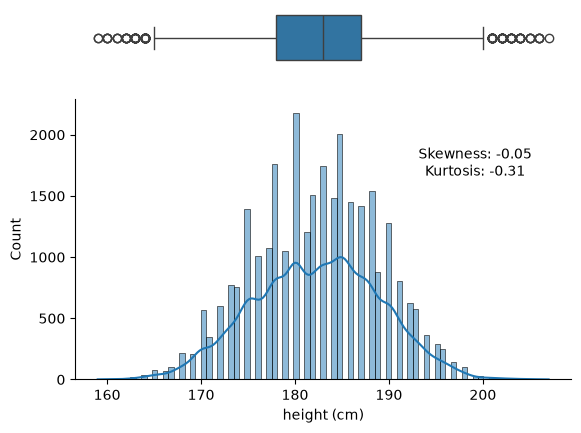

In [24]:
fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=[1,5])

# rid ourselves of mistakes
df = df.loc[df['height_in_cm']>140] # .loc helps to filter out outliers of your choosing

non_na_heights = df['height_in_cm'].dropna()
skewness = stats.skew(df['height_in_cm'], nan_policy= 'omit')
kurt = stats.kurtosis(df['height_in_cm'], nan_policy= 'omit')

txt = f"""Skewness: {skewness:.2f}
Kurtosis: {kurt:.2f}
"""

plt.figtext(x=0.75, y=0.5, s=txt, transform=fig.transFigure, ha="center")

box = sns.boxplot(data=df, x="height_in_cm", ax=ax1)
hist = sns.histplot(data=df, x="height_in_cm", ax=ax2, kde=True) #x is where variables are 

ax1.spines.clear()
ax1.set(xticks=[], xlabel="", yticks=[])
ax2.spines[["right","top"]].set_visible(False)
ax2.set(xlabel="height (cm)")



plt.show()

In [25]:
df.info()

<class 'pandas.DataFrame'>
Index: 30055 entries, 0 to 32400
Data columns (total 23 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   player_id                             30055 non-null  int64  
 1   first_name                            28024 non-null  str    
 2   last_name                             30055 non-null  str    
 3   name                                  30055 non-null  str    
 4   last_season                           30055 non-null  int64  
 5   current_club_id                       30055 non-null  int64  
 6   player_code                           30055 non-null  str    
 7   country_of_birth                      28161 non-null  str    
 8   city_of_birth                         28489 non-null  str    
 9   country_of_citizenship                29707 non-null  str    
 10  date_of_birth                         30019 non-null  str    
 11  sub_position                   

In [ ]:
from numpy import nan

def evaluate_df(df):

    rows = [] # list of list
    columns = [
        'column_name',
        'is_numeric',
        'mean',
        'median',
        'min',
        'max',
        'Q25',
        'Q75',
        'std',
        'num_null',
        'num_unique',
        'uniques<5']

    for col in df.columns:    
        col_name = col
        is_numeric = pd.api.types.is_numeric_dtype(df[col])
        column_name = nan
        mean = nan
        median = nan
        min = nan
        max = nan
        Q25 = nan
        Q75 = nan
        std = nan
        num_null = df[col].isna().sum()
        num_unique = nan
        uniques5 = nan
            #print(f'{col} is number' )

        if is_numeric:
            mean= df[col].mean()
            median= df[col].median()
            minimum= df[col].min()
            maximum= df[col].max()
            Q25= df[col].quantile(0.25)
            Q75= df[col].quantile(0.75)
            std= df[col].std()

        else:
            num_unique = df[col].nunique()
            uniques5 = df[col].unique() if num_unique <=5 else nan

            # print(f'{col} is categorical')    
        row = [
            column_name,
            is_numeric,
            mean,
            median,
            min,
            max,
            Q25, 
            Q75,
            std,
            num_null,
            num_unique,
            uniques5, 
        ]    
        rows.append(row)

    eval_df = pd.DataFrame(data= rows, columns= columns)

    return eval_df.sort_values(by='is_numeric')    
        

True
True
True
True
True
True


,column_name,is_numeric,mean,median,min,max,Q25,Q75,std,num_null,num_unique,uniques<5
11,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107,13.0,NaN
17,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,25452.0,NaN
13,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1221,3.0,"[right, left, both, nan]"
12,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,5.0,"[Attack, Goalkeeper, Midfield, Defender, Missing]"
18,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,30055.0,NaN
10,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36,9007.0,NaN
9,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,348,183.0,NaN
15,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10916,108.0,NaN
8,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1566,8352.0,NaN
6,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,29368.0,NaN


In [ ]:
from numpy import nan